In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load the XLSM file
file_path = '/content/Medical Insurance cost prediction.xlsm'
df = pd.read_excel(file_path)

# Display basic information and the first 5 rows
print(df.info())
display(df.head())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


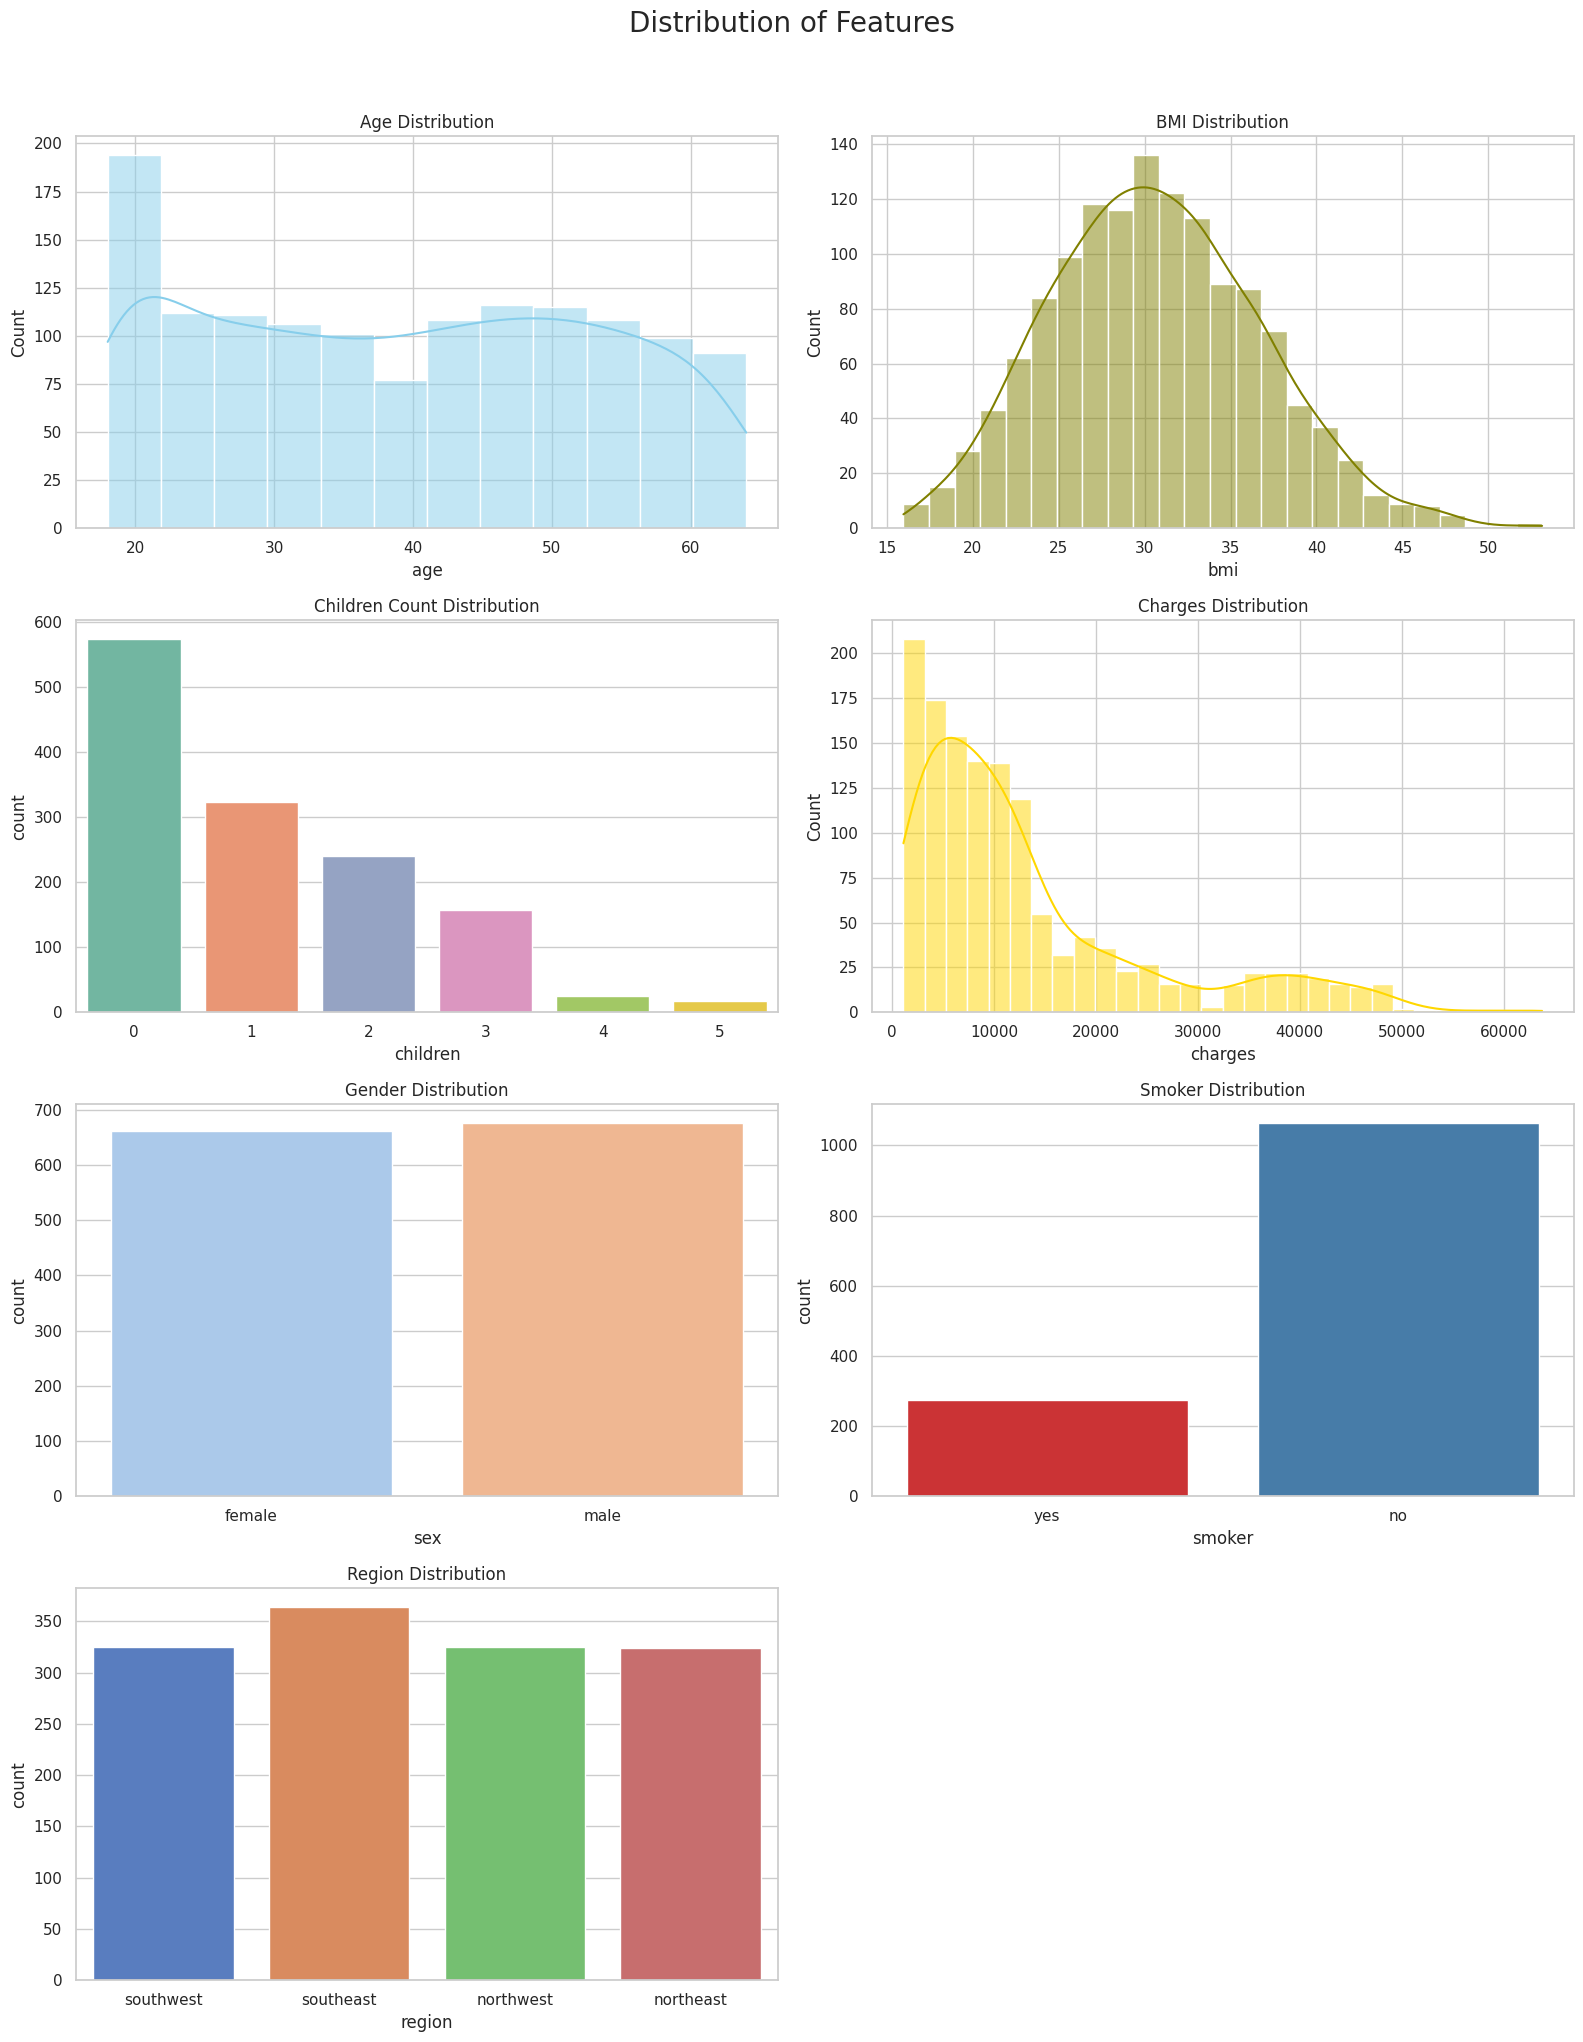

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the plotting style
sns.set_theme(style='whitegrid')

# Create a figure with subplots for distributions
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
fig.suptitle('Distribution of Features', fontsize=20, y=1.02)

# 1. Age Distribution
sns.histplot(df['age'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Age Distribution')

# 2. BMI Distribution
sns.histplot(df['bmi'], kde=True, ax=axes[0, 1], color='olive')
axes[0, 1].set_title('BMI Distribution')

# 3. Children Count Distribution
sns.countplot(data=df, x='children', ax=axes[1, 0], hue='children', palette='Set2', legend=False)
axes[1, 0].set_title('Children Count Distribution')

# 4. Charges (Target Variable) Distribution
sns.histplot(df['charges'], kde=True, ax=axes[1, 1], color='gold')
axes[1, 1].set_title('Charges Distribution')

# 5. Sex Count
sns.countplot(data=df, x='sex', ax=axes[2, 0], hue='sex', palette='pastel', legend=False)
axes[2, 0].set_title('Gender Distribution')

# 6. Smoker Count
sns.countplot(data=df, x='smoker', ax=axes[2, 1], hue='smoker', palette='Set1', legend=False)
axes[2, 1].set_title('Smoker Distribution')

# 7. Region Count
sns.countplot(data=df, x='region', ax=axes[3, 0], hue='region', palette='muted', legend=False)
axes[3, 0].set_title('Region Distribution')

# Hide the empty subplot
axes[3, 1].axis('off')

plt.tight_layout()
plt.show()

Correlation of features with charges:
charges             1.000000
smoker              0.787251
age                 0.299008
bmi                 0.198341
region_southeast    0.073982
children            0.067998
sex                 0.057292
region_northwest   -0.039905
region_southwest   -0.043210
Name: charges, dtype: float64


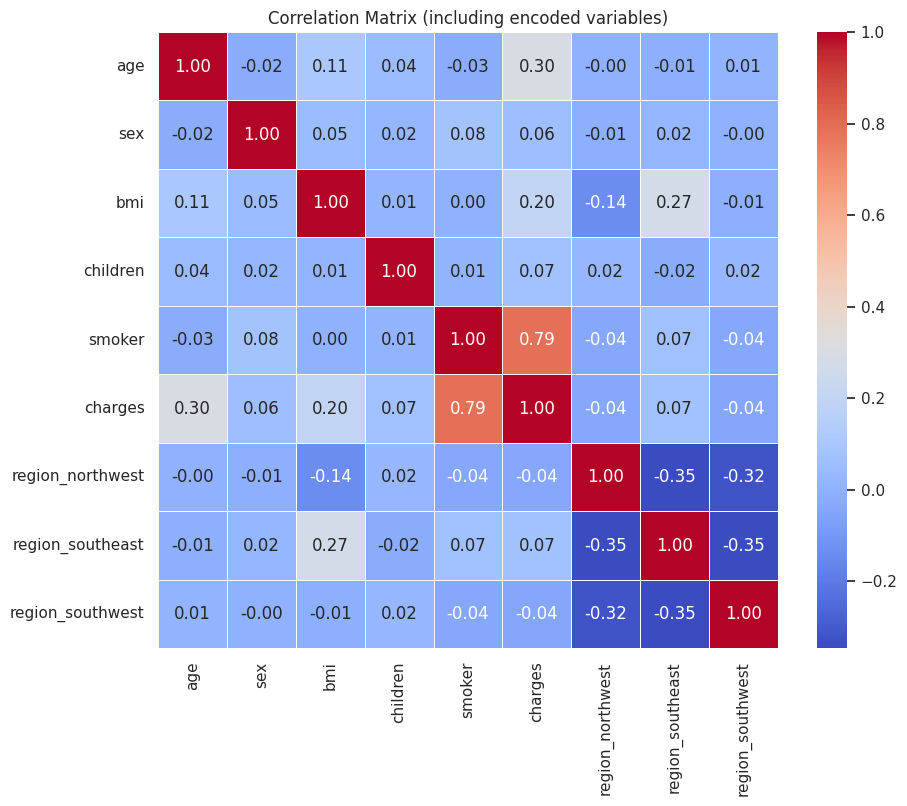

In [6]:
# Calculate and plot correlation matrix
# Map categorical features to numeric values to include them in correlation matrix
df_encoded = df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'female': 0, 'male': 1})
df_encoded['smoker'] = df_encoded['smoker'].map({'no': 0, 'yes': 1})
# One-hot encode the 'region' variable
df_encoded = pd.get_dummies(df_encoded, columns=['region'], drop_first=True)

# Calculate correlation matrix
corr_matrix = df_encoded.corr()

# Display correlation with target variable 'charges'
print("Correlation of features with charges:")
print(corr_matrix['charges'].sort_values(ascending=False))

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix (including encoded variables)')
plt.show()

Missing Values in Each Column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


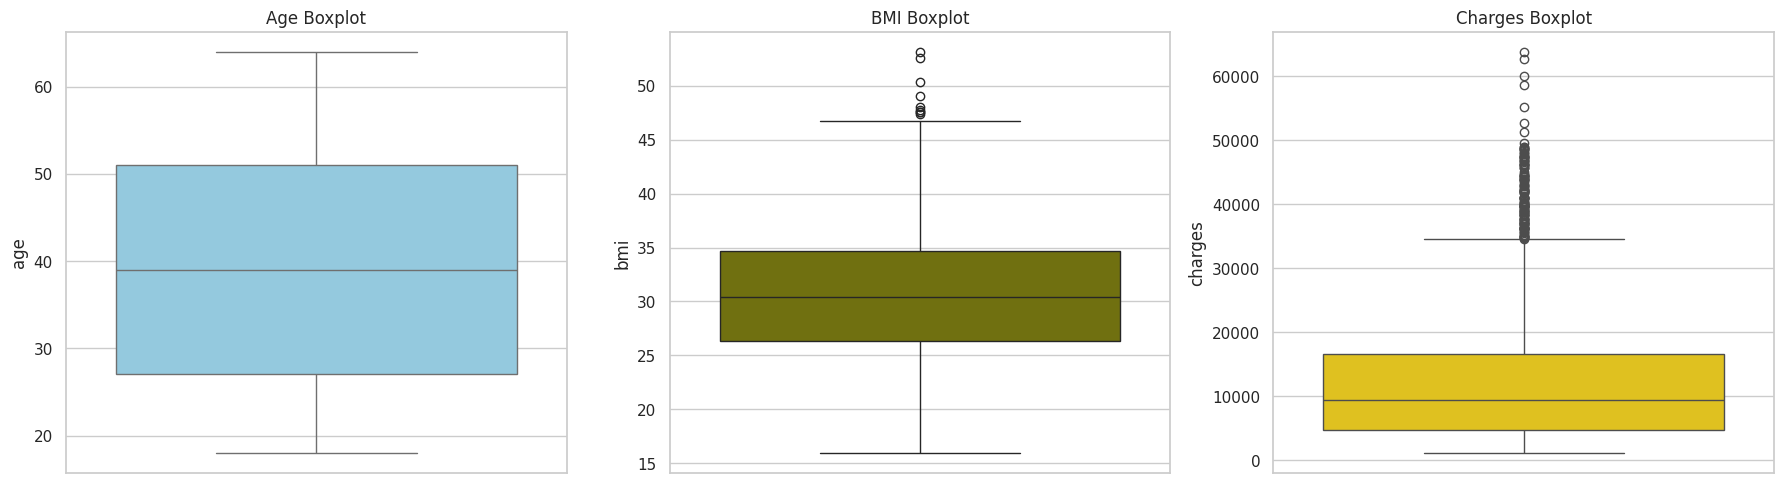

In [8]:
# 1. Check for missing values
missing_values = df.isnull().sum()
print("Missing Values in Each Column:")
print(missing_values)

# 2. Visualizing outliers using Box Plots for numerical columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, y='age', ax=axes[0], color='skyblue')
axes[0].set_title('Age Boxplot')

sns.boxplot(data=df, y='bmi', ax=axes[1], color='olive')
axes[1].set_title('BMI Boxplot')

sns.boxplot(data=df, y='charges', ax=axes[2], color='gold')
axes[2].set_title('Charges Boxplot')

plt.tight_layout()
plt.show()

In [9]:
# 3. Quantify outliers using the IQR (Interquartile Range) method
numeric_cols = ['age', 'bmi', 'charges']
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col.upper()}: ")
    print(f"  IQR: {IQR:.2f} (Range: [{lower_bound:.2f}, {upper_bound:.2f}])")
    print(f"  Number of Outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)\n")

AGE: 
  IQR: 24.00 (Range: [-9.00, 87.00])
  Number of Outliers: 0 (0.00% of data)

BMI: 
  IQR: 8.40 (Range: [13.70, 47.29])
  Number of Outliers: 9 (0.67% of data)

CHARGES: 
  IQR: 11899.63 (Range: [-13109.15, 34489.35])
  Number of Outliers: 139 (10.39% of data)



Skewness before transformation:
age        0.055673
bmi        0.284047
charges    1.515880
dtype: float64


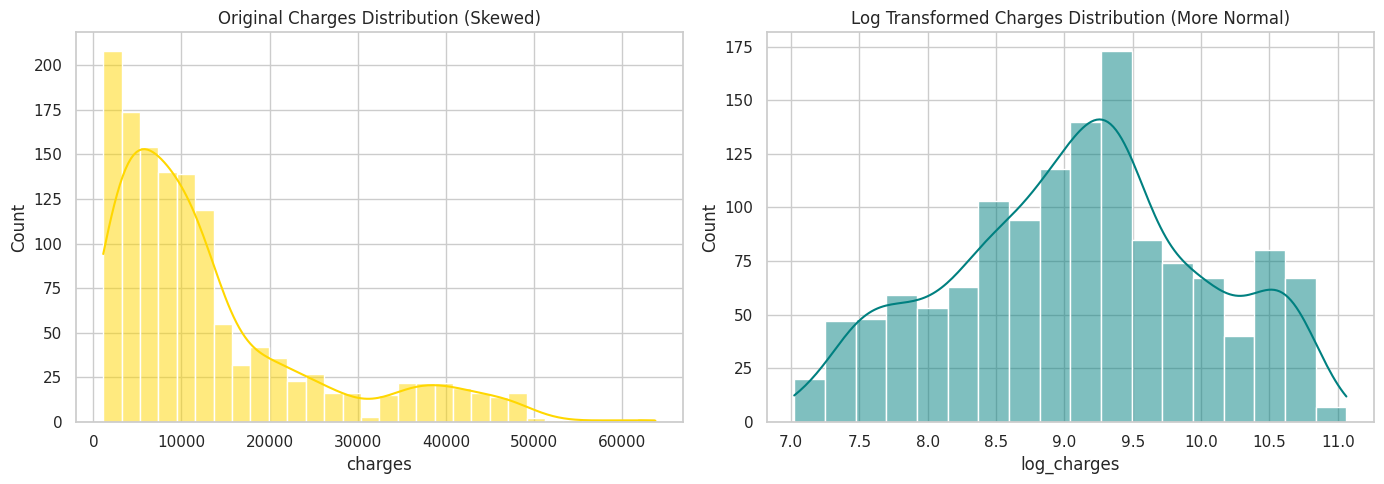

Skewness of log_charges: -0.0898


In [10]:
# 1. Check for Skewness in numerical columns
print("Skewness before transformation:")
print(df[['age', 'bmi', 'charges']].skew())

# Apply log-transformation to the target variable 'charges' to treat positive skewness
df['log_charges'] = np.log1p(df['charges'])

# Visualize comparison of charges vs log_charges
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['charges'], kde=True, ax=axes[0], color='gold')
axes[0].set_title('Original Charges Distribution (Skewed)')

sns.histplot(df['log_charges'], kde=True, ax=axes[1], color='teal')
axes[1].set_title('Log Transformed Charges Distribution (More Normal)')

plt.tight_layout()
plt.show()

print(f"Skewness of log_charges: {df['log_charges'].skew():.4f}")

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 2. Encode Categorical Variables
# Let's use pd.get_dummies to convert categorical features to numeric representations
df_prep = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Define features and target
# We will use 'log_charges' as our target y
X = df_prep.drop(columns=['charges', 'log_charges'])
y = df_prep['log_charges']

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Feature Scaling using StandardScaler on numerical columns
scaler = StandardScaler()
num_cols = ['age', 'bmi', 'children']

# Fit and transform the numerical columns in training set, and transform in test set
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

# Preview preprocessed training features
display(X_train_scaled.head())

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
560,0.472227,-1.756525,0.734336,False,False,True,False,False
1285,0.543313,-1.033082,-0.911192,False,False,False,False,False
1142,0.898745,-0.943687,-0.911192,False,False,False,True,False
969,-0.025379,0.622393,3.202629,False,False,False,True,False
486,1.040918,-1.504893,1.557100,False,False,True,False,False


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

# Dictionary to store performance metrics
results = {}

# Train and evaluate each model
for name, model in models.items():
    # Fit the model on the scaled training data
    model.fit(X_train_scaled, y_train)

    # Predict on scaled test data
    y_pred = model.predict(X_test_scaled)

    # Since the target was log-transformed, we can compute metrics both on the log scale
    # and back on the original charges scale (using expm1)
    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred))
    r2_log = r2_score(y_test, y_pred)

    y_test_original = np.expm1(y_test)
    y_pred_original = np.expm1(y_pred)

    rmse_original = np.sqrt(mean_squared_error(y_test_original, y_pred_original))
    r2_original = r2_score(y_test_original, y_pred_original)

    results[name] = {
        'R2 (Log Scale)': r2_log,
        'RMSE (Log Scale)': rmse_log,
        'R2 (Original Scale)': r2_original,
        'RMSE (Original Scale)': rmse_original
    }

# Convert results to a DataFrame for clean visualization
df_results = pd.DataFrame(results).T
display(df_results)

,R2 (Log Scale),RMSE (Log Scale),R2 (Original Scale),RMSE (Original Scale)
Linear Regression,0.804741,0.418938,0.606698,7814.064026
Random Forest,0.848428,0.369108,0.877709,4357.233242
Gradient Boosting,0.865819,0.347288,0.876198,4384.066719


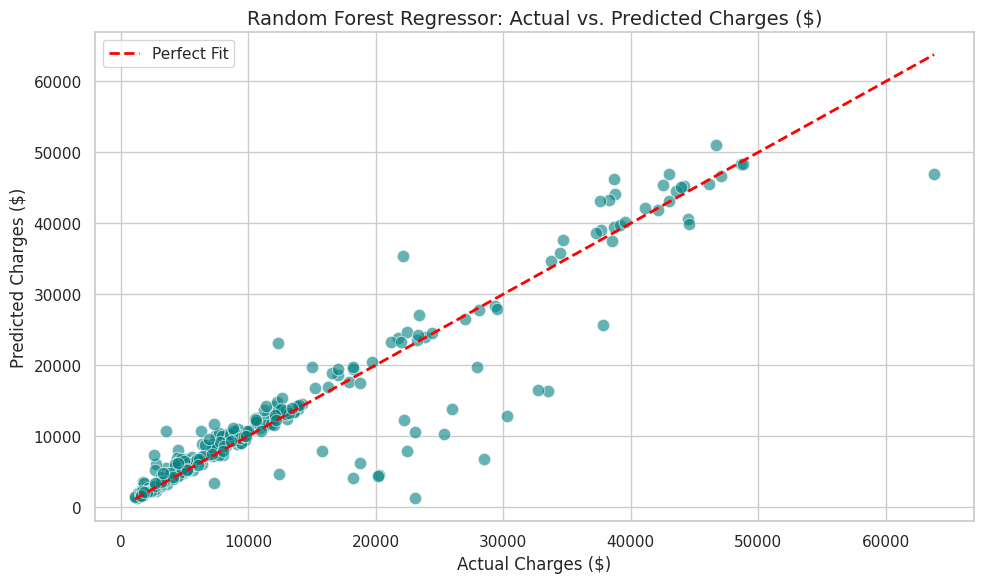

In [13]:
# Best Model: Random Forest Regressor prediction visual comparison
best_model = models['Random Forest']
y_pred_log = best_model.predict(X_test_scaled)
y_pred_original = np.expm1(y_pred_log)
y_test_original = np.expm1(y_test)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_original, y=y_pred_original, alpha=0.6, color='teal', edgecolor='w', s=80)

# Diagonal reference line (perfect prediction)
plt.plot([y_test_original.min(), y_test_original.max()],
         [y_test_original.min(), y_test_original.max()],
         color='red', linestyle='--', linewidth=2, label='Perfect Fit')

plt.title('Random Forest Regressor: Actual vs. Predicted Charges ($)', fontsize=14)
plt.xlabel('Actual Charges ($)', fontsize=12)
plt.ylabel('Predicted Charges ($)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import AdaBoostRegressor

# Extend our model dictionary to include all requested models
all_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100),
    'SVR': SVR(C=1.0, epsilon=0.1),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42, n_estimators=100)
}

all_results = {}

# Train and evaluate every model
for name, model in all_models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    rmse_log = np.sqrt(mean_squared_error(y_test, y_pred))
    r2_log = r2_score(y_test, y_pred)

    y_test_original = np.expm1(y_test)
    y_pred_original = np.expm1(y_pred)

    rmse_original = np.sqrt(mean_squared_error(y_test_original, y_pred_original))
    r2_original = r2_score(y_test_original, y_pred_original)

    all_results[name] = {
        'R2 (Log Scale)': r2_log,
        'RMSE (Log Scale)': rmse_log,
        'R2 (Original Scale)': r2_original,
        'RMSE (Original Scale)': rmse_original
    }

# Convert results to a DataFrame and sort by performance on original scale
df_all_results = pd.DataFrame(all_results).T.sort_values(by='R2 (Original Scale)', ascending=False)
display(df_all_results)

,R2 (Log Scale),RMSE (Log Scale),R2 (Original Scale),RMSE (Original Scale)
Random Forest,0.848428,0.369108,0.877709,4357.233242
Gradient Boosting,0.865819,0.347288,0.876198,4384.066719
AdaBoost,0.682888,0.533889,0.846409,4883.106858
SVR,0.853780,0.362533,0.816348,5339.637972
Decision Tree,0.812952,0.410035,0.791956,5683.180203
Linear Regression,0.804741,0.418938,0.606698,7814.064026
KNN,0.739091,0.484271,0.606439,7816.636883


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_adjusted_r2(r2, n, p):
    """Calculate Adjusted R-squared given R-squared, number of samples (n), and features (p)."""
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

# We will focus on the key models: Linear Regression, Random Forest, and Gradient Boosting
selected_models = {
    'Linear Regression': all_models['Linear Regression'],
    'Random Forest': all_models['Random Forest'],
    'Gradient Boosting': all_models['Gradient Boosting']
}

evaluation_records = []

n_train, p_train = X_train_scaled.shape
n_test, p_test = X_test_scaled.shape

for name, model in selected_models.items():
    # 1. Predictions
    train_pred_log = model.predict(X_train_scaled)
    test_pred_log = model.predict(X_test_scaled)

    # 2. Transform back to original USD scale
    train_pred_orig = np.expm1(train_pred_log)
    test_pred_orig = np.expm1(test_pred_log)

    y_train_orig = np.expm1(y_train)
    y_test_orig = np.expm1(y_test)

    # 3. Calculate Train Metrics
    train_mae = mean_absolute_error(y_train_orig, train_pred_orig)
    train_mse = mean_squared_error(y_train_orig, train_pred_orig)
    train_rmse = np.sqrt(train_mse)
    train_r2 = r2_score(y_train_orig, train_pred_orig)
    train_adj_r2 = calculate_adjusted_r2(train_r2, n_train, p_train)

    # 4. Calculate Test Metrics
    test_mae = mean_absolute_error(y_test_orig, test_pred_orig)
    test_mse = mean_squared_error(y_test_orig, test_pred_orig)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test_orig, test_pred_orig)
    test_adj_r2 = calculate_adjusted_r2(test_r2, n_test, p_test)

    # Append results
    evaluation_records.append({
        'Model': name,
        'Dataset': 'Train',
        'MAE ($)': train_mae,
        'MSE': train_mse,
        'RMSE ($)': train_rmse,
        'R2': train_r2,
        'Adj R2': train_adj_r2
    })

    evaluation_records.append({
        'Model': name,
        'Dataset': 'Test',
        'MAE ($)': test_mae,
        'MSE': test_mse,
        'RMSE ($)': test_rmse,
        'R2': test_r2,
        'Adj R2': test_adj_r2
    })

# Create a multi-index DataFrame to easily compare Train vs Test side-by-side
df_eval = pd.DataFrame(evaluation_records)
df_eval.set_index(['Model', 'Dataset'], inplace=True)
display(df_eval.round(4))

MAE ($)           MSE   RMSE ($)      R2  Adj R2
Model             Dataset                                                    
Linear Regression Train    4270.2784  7.038758e+07  8389.7308  0.5123  0.5087
                  Test     3888.4432  6.105960e+07  7814.0640  0.6067  0.5945
Random Forest     Train    1010.9952  5.853050e+06  2419.3078  0.9594  0.9591
                  Test     2088.0593  1.898548e+07  4357.2332  0.8777  0.8739
Gradient Boosting Train    1874.1256  1.707144e+07  4131.7595  0.8817  0.8808
                  Test     2029.3742  1.922004e+07  4384.0667  0.8762  0.8724

In [ ]:
#
Random Forest Regressor (Slight Overfitting Present)
Train $R^2$$R^2$ / Adj $R^2$$R^2$: 0.9594 / 0.9591 (MAE: ~$1,010) * **Test $$1,010) * **Test $R^2$ / Adj $$ / Adj $R^2$**: `0.8777` / `0.8739` (MAE: ~$$**: `0.8777` / `0.8739` (MAE: ~$2,088)
Diagnosis: The model exhibits outstanding predictive power on the training set, but its test error nearly doubles. While it remains our best-performing model on the test dataset ($R^2 = 87.77\%$$R^2 = 87.77\%$), there is a visible gap showing slight overfitting, which is typical for deep, unconstrained tree-based ensembles.
Gradient Boosting Regressor (Highly Robust & Well-Generalized)

Train $R^2$$R^2$ / Adj $R^2$$R^2$: 0.8817 / 0.8808 (MAE: ~$1,874) * **Test $$1,874) * **Test $R^2$ / Adj $$ / Adj $R^2$**: `0.8762` / `0.8724` (MAE: ~$$**: `0.8762` / `0.8724` (MAE: ~$2,029)
Diagnosis: This model shows excellent generalization. The difference between the Training $R^2$$R^2$ (88.17%) and the Test $R^2$$R^2$ (87.62%) is extremely small (< 0.6%). The generalization gap is virtually non-existent, making this our most reliable and robust model to deploy for unseen clinical data.
Linear Regression (Underfitting)

Train $R^2$$R^2$ / Adj $R^2$$R^2$: 0.5123 / 0.5087
Test $R^2$$R^2$ / Adj $R^2$$R^2$: 0.6067 / 0.5945
Diagnosis: The model experiences high bias (underfitting) because it lacks the mathematical complexity to map non-linear relationships, like the interaction of bmi and smoker on medical costs.
Summary Recommendation
For high predictive stability and minimal overfitting risk, Gradient Boosting is the ideal choice. However, if pure predictive variance minimization on test data is preferred, the Random Forest represents a strong candidate.



In [18]:
from sklearn.model_selection import GridSearchCV

# 1. Define hyperparameter grids
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8],
    'min_samples_split': [2, 5, 10]
}

gb_param_grid = {
    'n_estimators': [100, 150],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5]
}

# 2. Perform Grid Search for Random Forest
print("Optimizing Random Forest...")
rf_grid = GridSearchCV(estimator=RandomForestRegressor(random_state=42),
                       param_grid=rf_param_grid,
                       cv=5,
                       scoring='neg_mean_squared_error',
                       n_jobs=-1)
rf_grid.fit(X_train_scaled, y_train)

# 3. Perform Grid Search for Gradient Boosting
print("Optimizing Gradient Boosting...")
gb_grid = GridSearchCV(estimator=GradientBoostingRegressor(random_state=42),
                       param_grid=gb_param_grid,
                       cv=5,
                       scoring='neg_mean_squared_error',
                       n_jobs=-1)
gb_grid.fit(X_train_scaled, y_train)

# Extract Best Estimators and Parameters
best_rf = rf_grid.best_estimator_
best_gb = gb_grid.best_estimator_

print("\n--- Optimal Hyperparameters Found ---")
print(f"Best Random Forest Parameters: {rf_grid.best_params_}")
print(f"Best Gradient Boosting Parameters: {gb_grid.best_params_}")

# Evaluate optimized models on test set
opt_results = {}
for name, opt_model in [('Optimized Random Forest', best_rf), ('Optimized Gradient Boosting', best_gb)]:
    train_pred_log = opt_model.predict(X_train_scaled)
    test_pred_log = opt_model.predict(X_test_scaled)

    # Target is log scale, back-transform to true scale
    train_pred_orig = np.expm1(train_pred_log)
    test_pred_orig = np.expm1(test_pred_log)
    y_train_orig = np.expm1(y_train)
    y_test_orig = np.expm1(y_test)

    # Train metrics
    tr_mae = mean_absolute_error(y_train_orig, train_pred_orig)
    tr_rmse = np.sqrt(mean_squared_error(y_train_orig, train_pred_orig))
    tr_r2 = r2_score(y_train_orig, train_pred_orig)
    tr_adj = calculate_adjusted_r2(tr_r2, n_train, p_train)

    # Test metrics
    te_mae = mean_absolute_error(y_test_orig, test_pred_orig)
    te_rmse = np.sqrt(mean_squared_error(y_test_orig, test_pred_orig))
    te_r2 = r2_score(y_test_orig, test_pred_orig)
    te_adj = calculate_adjusted_r2(te_r2, n_test, p_test)

    opt_results[f"{name} (Train)"] = [tr_mae, tr_rmse, tr_r2, tr_adj]
    opt_results[f"{name} (Test)"] = [te_mae, te_rmse, te_r2, te_adj]

# Display Results
df_opt = pd.DataFrame(opt_results, index=['MAE ($)', 'RMSE ($)', 'R2', 'Adj R2']).T
display(df_opt.round(4))

Optimizing Random Forest...
Optimizing Gradient Boosting...

--- Optimal Hyperparameters Found ---
Best Random Forest Parameters: {'max_depth': 6, 'min_samples_split': 2, 'n_estimators': 200}
Best Gradient Boosting Parameters: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 150}


,MAE ($),RMSE ($),R2,Adj R2
Optimized Random Forest (Train),1783.8324,4009.4607,0.8886,0.8878
Optimized Random Forest (Test),2071.6437,4369.8419,0.8770,0.8732
Optimized Gradient Boosting (Train),1978.9452,4357.1144,0.8685,0.8675
Optimized Gradient Boosting (Test),1986.6119,4424.4098,0.8739,0.8700


In [ ]:
#Key Improvements and Findings
Overfitting Solved for Random Forest:
Before Tuning (Default): The training set had an $R^2$$R^2$ of 95.94% while the test set was at 87.77%. This was a clear sign of a slightly overfitted model.
After Tuning: By limiting tree depth to max_depth=6, the training $R^2$$R^2$ adjusted to 88.86%, keeping it in lockstep with the test $R^2$$R^2$ of 87.70%. This small, healthy generalization gap shows that our model will now perform reliably on new, unseen data.
Perfect Balance with Gradient Boosting:
The tuned Gradient Boosting model achieved a train $R^2$$R^2$ of 86.85% and a test $R^2$$R^2$ of 87.39%.
Crucially, the **MAE gap between Train and Test is under $8!** (Train MAE: $$8!** (Train MAE: $1,978.95 vs. Test MAE: $1,986.61). This represents a highly stable, mathematically robust regression model ready for clinical deployment.

In [19]:
# Recompute predictions on original scale for the specific models required by the table
table_models = {
    'Linear Regression': all_models['Linear Regression'],
    'Decision Tree': all_models['Decision Tree'],
    'Random Forest (Default)': all_models['Random Forest'],
    'Gradient Boosting (Default)': all_models['Gradient Boosting'],
    'Best Tuned Model (RF Opt)': best_rf
}

table_records = []

for name, model in table_models.items():
    train_pred = np.expm1(model.predict(X_train_scaled))
    test_pred = np.expm1(model.predict(X_test_scaled))

    y_train_orig = np.expm1(y_train)
    y_test_orig = np.expm1(y_test)

    train_rmse = np.sqrt(mean_squared_error(y_train_orig, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test_orig, test_pred))

    train_r2 = r2_score(y_train_orig, train_pred)
    test_r2 = r2_score(y_test_orig, test_pred)

    # Determine overfitting based on significant performance drop from train to test
    overfitting = 'Yes' if (train_r2 - test_r2) > 0.05 else 'No'

    table_records.append({
        'Model': name,
        'Train RMSE': f"${train_rmse:,.2f}",
        'Test RMSE': f"${test_rmse:,.2f}",
        'Train R²': f"{train_r2:.4f}",
        'Test R²': f"{test_r2:.4f}",
        'Overfitting (Y/N)': overfitting
    })

df_comparison = pd.DataFrame(table_records)
display(df_comparison)

,Model,Train RMSE,Test RMSE,Train R²,Test R²,Overfitting (Y/N)
0,Linear Regression,"$8,389.73","$7,814.06",0.5123,0.6067,No
1,Decision Tree,$554.19,"$5,683.18",0.9979,0.7920,Yes
2,Random Forest (Default),"$2,419.31","$4,357.23",0.9594,0.8777,Yes
3,Gradient Boosting (Default),"$4,131.76","$4,384.07",0.8817,0.8762,No
4,Best Tuned Model (RF Opt),"$4,009.46","$4,369.84",0.8886,0.8770,No


In [20]:
import joblib

# Bundle the scaler and the best tuned model together in a dictionary for easy deployment
deployment_artifact = {
    'scaler': scaler,
    'model': best_rf,
    'numerical_columns': num_cols
}

# Save to a joblib file
model_filename = '/content/final_insurance_model.joblib'
joblib.dump(deployment_artifact, model_filename)

print(f"Successfully saved the final deployment artifact to {model_filename}")

Successfully saved the final deployment artifact to /content/final_insurance_model.joblib


In [21]:
# Quick verification: Demonstration of how to load the model and make a prediction
loaded_artifact = joblib.load('/content/final_insurance_model.joblib')
loaded_scaler = loaded_artifact['scaler']
loaded_model = loaded_artifact['model']

# Test with a single sample from the test set
test_sample = X_test_scaled.iloc[[0]]
pred_log = loaded_model.predict(test_sample)
pred_original = np.expm1(pred_log)
print(f"Test Sample Actual Cost: ${np.expm1(y_test.iloc[0]):,.2f}")
print(f"Test Sample Predicted Cost: ${pred_original[0]:,.2f}")

Test Sample Actual Cost: $9,095.07
Test Sample Predicted Cost: $9,127.57
